In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler as standardization
from sklearn.feature_selection import VarianceThreshold
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve, roc_auc_score, fbeta_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline
import pickle
dataset_candidates = [
    Path(r"C:\Users\happy\OneDrive\dataset\uci-secom.csv"),
    Path("uci-secom.csv"),
]
csv_path = next((path for path in dataset_candidates if path.exists()), None)
if csv_path is None:
    raise FileNotFoundError("uci-secom.csv not found in dataset folder or project root")

print("Loading VectraYield from:", csv_path)
vectrayield = pd.read_csv(csv_path)
vectrayield.sample(10)

Loading VectraYield from: C:\Users\happy\OneDrive\dataset\uci-secom.csv


,Time,0,1,2,3,4,5,6,7,8,...,581,582,583,584,585,586,587,588,589,Pass/Fail
1397,2008-07-10 11:16:00,2984.41,2550.88,2192.1889,1435.9611,2.3870,100.0,107.3989,0.1229,1.5613,...,NaN,0.5012,0.0126,0.0034,2.5174,0.0106,0.0075,0.0025,71.0842,-1
621,2008-01-09 00:53:00,2931.40,2573.21,2171.8556,940.9917,1.2906,100.0,103.4733,0.1234,1.4002,...,NaN,0.5051,0.0086,0.0025,1.7063,0.0227,0.0149,0.0052,65.4831,-1
166,2008-09-08 06:05:00,3090.97,2469.60,2218.7889,1622.3514,1.2043,100.0,98.2667,0.1224,1.5129,...,23.3511,0.5011,0.0100,0.0029,1.9957,0.0419,0.0098,0.0031,23.3511,-1
430,2008-08-23 03:26:00,2956.84,2592.29,2217.3777,1425.1041,1.7585,100.0,106.2556,0.1200,1.5383,...,NaN,0.5009,0.0124,0.0035,2.4736,0.0142,0.0156,0.0044,109.5996,-1
303,2008-08-19 11:13:00,2889.93,NaN,2238.5444,1659.1424,0.9010,100.0,99.3100,0.1204,1.5386,...,NaN,0.5045,0.0125,0.0031,2.4807,0.0187,0.0108,0.0033,58.0827,-1
1252,2008-02-10 19:25:00,2958.99,2459.56,2191.8445,1093.0818,0.8725,100.0,101.4244,0.1229,1.4346,...,NaN,0.5001,0.0146,0.0042,2.9144,0.0243,0.0100,0.0031,41.0782,-1
1119,2008-09-27 03:53:00,3059.62,2376.27,2266.8333,2040.1937,1.6558,100.0,94.8489,0.1216,1.4303,...,NaN,0.5024,0.0105,0.0029,2.0848,0.0154,0.0123,0.0038,79.9402,-1
1093,2008-09-26 00:19:00,3162.14,2266.53,2169.9444,1095.3519,1.3425,100.0,104.0144,0.1208,1.4635,...,78.0627,0.5003,0.0082,0.0023,1.6366,0.0186,0.0146,0.0051,78.0627,-1
1308,2008-05-10 04:48:00,3282.87,2419.55,2189.6778,1295.2883,2.1394,100.0,107.4811,0.1238,1.5675,...,NaN,0.5005,0.0135,0.0033,2.6936,0.0230,0.0064,0.0024,27.7025,-1
1488,2008-10-13 20:30:00,2970.42,2494.39,2191.5000,1147.9162,0.9431,100.0,97.7200,0.1212,1.3264,...,NaN,0.4998,0.0161,0.0041,3.2243,0.0055,0.0205,0.0060,372.2183,-1


In [2]:
vectrayield.shape

(1567, 592)

In [3]:
vectrayield.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1567 entries, 0 to 1566
Columns: 592 entries, Time to Pass/Fail
dtypes: float64(590), int64(1), object(1)
memory usage: 7.1+ MB


In [4]:
print("Total Missing Values",vectrayield.isnull().sum().sum())

Total Missing Values 41951


In [5]:
print("Total duplicate values",vectrayield.duplicated().sum().sum())

Total duplicate values 0


In [6]:
vectrayield_missing=vectrayield.isnull().mean()
print(vectrayield_missing*100)

Time         0.000000
0            0.382897
1            0.446713
2            0.893427
3            0.893427
               ...   
586          0.063816
587          0.063816
588          0.063816
589          0.063816
Pass/Fail    0.000000
Length: 592, dtype: float64


In [7]:
vectrayield_HighNulls = vectrayield_missing[vectrayield_missing >= 0.50]
print("Columns with missing values >= 50%")
print(vectrayield_HighNulls)
print("Count:", len(vectrayield_HighNulls))

Columns with missing values >= 50%
72     0.506701
73     0.506701
85     0.855775
109    0.649649
110    0.649649
111    0.649649
157    0.911934
158    0.911934
220    0.855775
244    0.649649
245    0.649649
246    0.649649
292    0.911934
293    0.911934
345    0.506701
346    0.506701
358    0.855775
382    0.649649
383    0.649649
384    0.649649
492    0.855775
516    0.649649
517    0.649649
518    0.649649
578    0.605616
579    0.605616
580    0.605616
581    0.605616
dtype: float64
Count: 28


In [8]:
num_cols = vectrayield.select_dtypes(include=['float64', 'int64']).columns

outlier_info = {}

for col in num_cols:
    Q1 = vectrayield[col].quantile(0.25)
    Q3 = vectrayield[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = vectrayield[(vectrayield[col] < lower_bound) | (vectrayield[col] > upper_bound)]
    
    if len(outliers) > 0:
        outlier_info[col] = len(outliers)
print("columns with outliers count is ",len(outlier_info))


columns with outliers count is  453


In [11]:
vectrayield_clean = vectrayield.drop(columns=vectrayield_HighNulls.index, errors="ignore")
print("Shape after dropping high-null columns:", vectrayield_clean.shape)
print("Missing values before SimpleImputer:", int(vectrayield_clean.isnull().sum().sum()))

Shape after dropping high-null columns: (1567, 564)
Missing values before SimpleImputer: 11683


In [12]:
target_col = "Pass/Fail"
exclude = {target_col}
if "Time" in vectrayield_clean.columns:
    exclude.add("Time")

numeric_cols = [
    col for col in vectrayield_clean.columns
    if col not in exclude and pd.api.types.is_numeric_dtype(vectrayield_clean[col])
]

imputer = SimpleImputer(strategy="median")
vectrayield_imputed = vectrayield_clean.copy()
vectrayield_imputed[numeric_cols] = imputer.fit_transform(vectrayield_clean[numeric_cols])

print("Numeric feature columns:", len(numeric_cols))
print("Missing values after SimpleImputer:", int(vectrayield_imputed.isnull().sum().sum()))

Numeric feature columns: 562
Missing values after SimpleImputer: 0


In [13]:
def iqr_bounds(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


def outlier_column_count(df, cols):
    count = 0
    for col in cols:
        lower, upper = iqr_bounds(df[col])
        if ((df[col] < lower) | (df[col] > upper)).any():
            count += 1
    return count


outlier_cols_before = outlier_column_count(vectrayield_imputed, numeric_cols)

vectrayield_capped = vectrayield_imputed.copy()
for col in numeric_cols:
    lower, upper = iqr_bounds(vectrayield_imputed[col])
    vectrayield_capped[col] = vectrayield_imputed[col].clip(lower=lower, upper=upper)

outlier_cols_after = outlier_column_count(vectrayield_capped, numeric_cols)

print("Shape after IQR capping:", vectrayield_capped.shape)
print("Columns with IQR outliers before capping:", outlier_cols_before)
print("Columns with IQR outliers after capping:", outlier_cols_after)
print("Remaining missing values:", int(vectrayield_capped.isnull().sum().sum()))
vectrayield_capped.head()

Shape after IQR capping: (1567, 564)
Columns with IQR outliers before capping: 426
Columns with IQR outliers after capping: 0
Remaining missing values: 0


,Time,0,1,2,3,4,5,6,7,8,...,577,582,583,584,585,586,587,588,589,Pass/Fail
0,2008-07-19 11:55:00,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,1.5005,...,14.9509,0.500500,0.01180,0.0035,2.363000,0.020500,0.01480,0.00460,71.9005,-1
1,2008-07-19 12:32:00,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,1.4966,...,10.9003,0.501900,0.02230,0.0055,4.444700,0.009600,0.02010,0.00600,208.2045,-1
2,2008-07-19 13:17:00,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,1.4436,...,9.2721,0.495800,0.01570,0.0039,3.174500,0.048825,0.03485,0.01105,82.8602,1
3,2008-07-19 14:43:00,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,1.4882,...,8.5831,0.499000,0.01030,0.0025,2.054400,0.020200,0.01490,0.00440,73.8432,-1
4,2008-07-19 15:22:00,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,1.5031,...,10.9698,0.491225,0.02385,0.0056,4.777625,0.020200,0.01490,0.00440,73.8432,-1


In [14]:

target_col = "Pass/Fail"
feature_cols = [
    col
    for col in vectrayield.columns
    if col != target_col
    and col != "Time"
    and pd.api.types.is_numeric_dtype(vectrayield[col])
]

imputer = SimpleImputer(strategy="median")
vectrayield[feature_cols] = imputer.fit_transform(vectrayield[feature_cols])

for col in feature_cols:
    q1 = vectrayield[col].quantile(0.25)
    q3 = vectrayield[col].quantile(0.75)
    iqr = q3 - q1
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr
    vectrayield[col] = vectrayield[col].clip(
        lower=lower_limit, upper=upper_limit
    )

print(
    "Missing values remaining in features:",
    vectrayield[feature_cols].isnull().sum().sum(),
)

outlier_count = 0
for col in feature_cols:
    q1 = vectrayield[col].quantile(0.25)
    q3 = vectrayield[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    if ((vectrayield[col] < lower) | (vectrayield[col] > upper)).any():
        outlier_count += 1

print("Columns with outliers after capping:", outlier_count)
print("Updated DataFrame shape:", vectrayield.shape)
vectrayield[feature_cols].head()

Missing values remaining in features: 0
Columns with outliers after capping: 0
Updated DataFrame shape: (1567, 592)


,0,1,2,3,4,5,6,7,8,9,...,580,581,582,583,584,585,586,587,588,589
0,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,1.5005,0.0162,...,0.0047,72.2889,0.500500,0.01180,0.0035,2.363000,0.020500,0.01480,0.00460,71.9005
1,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,1.4966,-0.0005,...,0.0047,72.2889,0.501900,0.02230,0.0055,4.444700,0.009600,0.02010,0.00600,208.2045
2,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,1.4436,0.0041,...,0.0047,72.2889,0.495800,0.01570,0.0039,3.174500,0.048825,0.03485,0.01105,82.8602
3,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,1.4882,-0.0124,...,0.0047,72.2889,0.499000,0.01030,0.0025,2.054400,0.020200,0.01490,0.00440,73.8432
4,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,1.5031,-0.0031,...,0.0047,72.2889,0.491225,0.02385,0.0056,4.777625,0.020200,0.01490,0.00440,73.8432


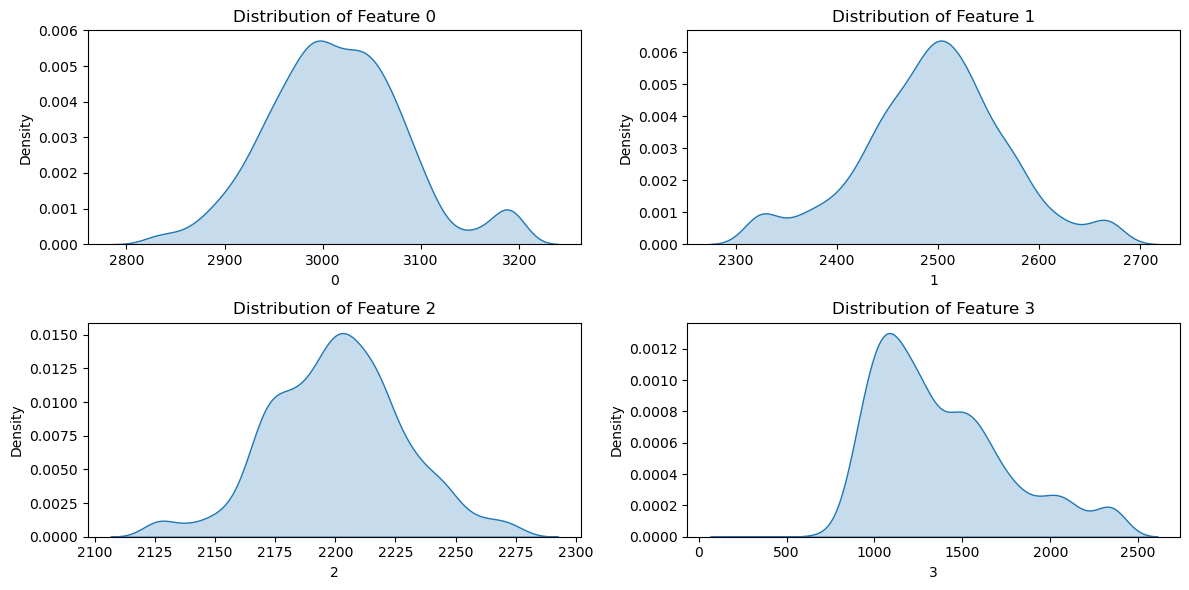

In [15]:

sample_features = feature_cols[:4]

plt.figure(figsize=(12, 6))
for i, col in enumerate(sample_features, 1):
    plt.subplot(2, 2, i)
    sns.kdeplot(vectrayield[col], fill=True)
    plt.title(f"Distribution of Feature {col}")

plt.tight_layout()
plt.show()

In [16]:
X = vectrayield[feature_cols]
y = vectrayield[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
scaler = standardization()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(X_train_scaled)
print(X_test_scaled )

[[ 0.89324424 -0.07504817 -0.55394758 ... -0.75661456 -0.73100625
  -0.68166368]
 [ 0.83930169 -0.09737201  0.61753161 ... -1.4324185  -1.23068394
  -1.18748209]
 [ 0.05973083  0.38566015  0.02554405 ...  1.00047569  0.68474719
  -0.27460129]
 ...
 [-0.5430123   0.29162096 -1.37216869 ... -1.21616124 -1.31396355
  -1.0714481 ]
 [-1.22926542  0.37338204  0.37194624 ... -0.22948749 -0.18968876
   2.20108859]
 [-1.20503454  0.11233259 -0.61887349 ... -0.52684122 -0.48116741
  -0.41519283]]
[[-0.40858861  0.18628033 -0.83623321 ...  1.48705453  2.18378024
   1.46417143]
 [-1.02662027 -0.52222266  0.38082006 ... -1.21616124 -1.23068394
  -0.26501554]
 [ 1.45776604  2.23784154  0.24249727 ...  0.44631646  0.30998892
  -0.3210059 ]
 ...
 [-0.60056064  0.97459105  0.21910957 ...  0.66257372  0.06015008
   0.05640074]
 [ 0.42881905 -0.31781996 -0.71888095 ... -0.0267463   0.06015008
  -0.28329519]
 [ 0.34040519 -0.67067622 -0.1962544  ...  0.28412351  0.47654815
  -0.1400963 ]]


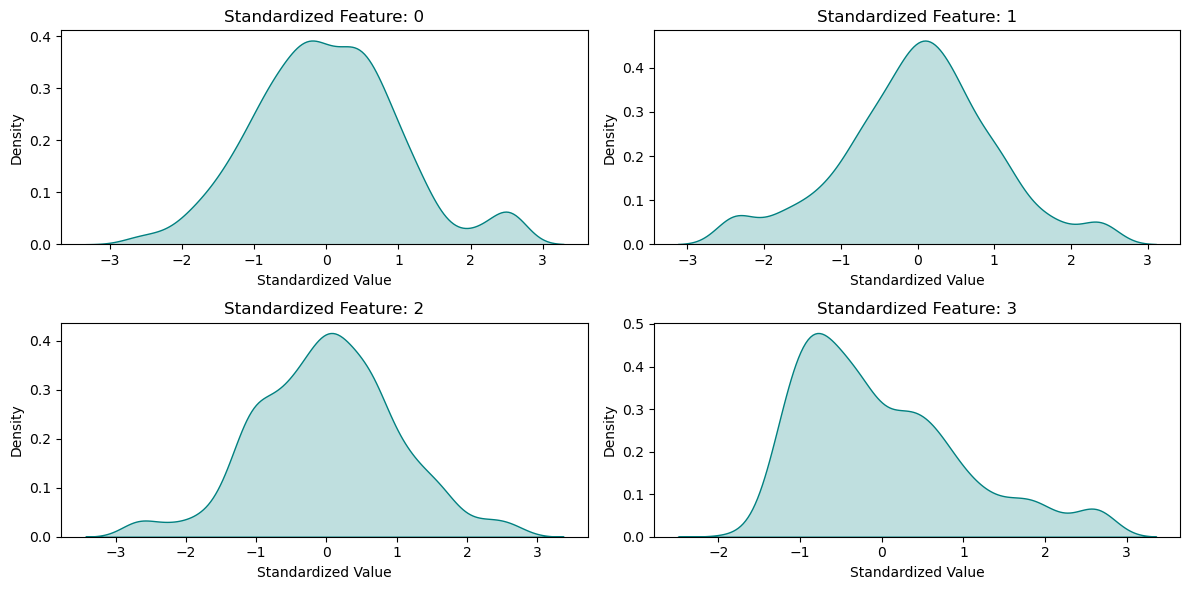

In [17]:
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=feature_cols)
sample_features = feature_cols[:4]

plt.figure(figsize=(12, 6))
for i, col in enumerate(sample_features, 1):
    plt.subplot(2, 2, i)
    sns.kdeplot(X_train_scaled_df[col], fill=True, color="teal")
    plt.title(f"Standardized Feature: {col}")
    plt.xlabel("Standardized Value")
    plt.ylabel("Density")

plt.tight_layout()
plt.show()

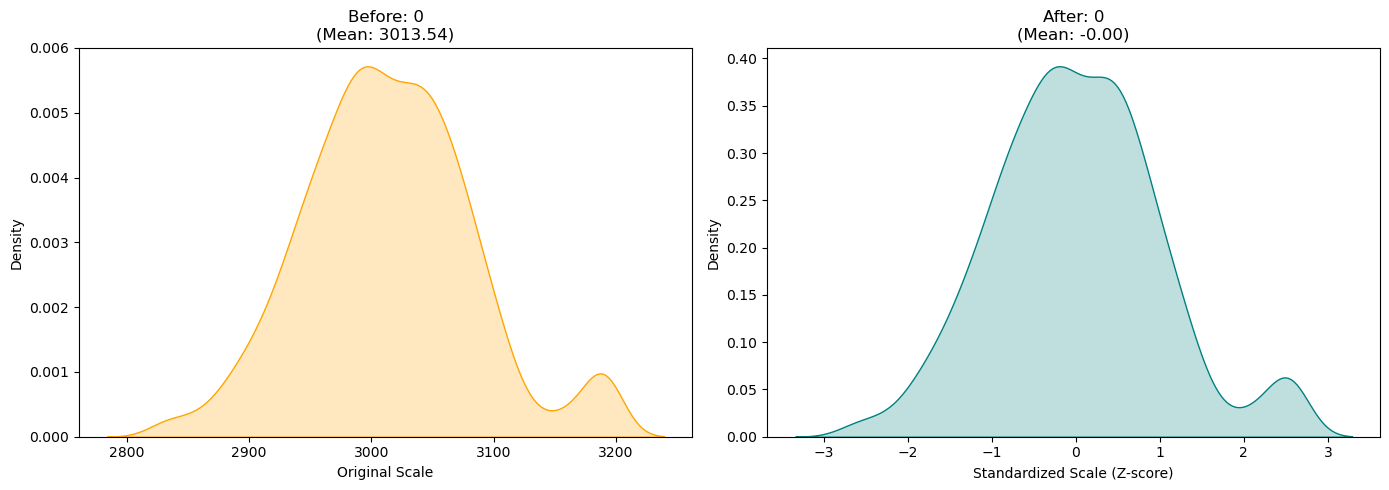

In [19]:

col_to_check = feature_cols[0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.kdeplot(vectrayield[col_to_check], fill=True, color="orange", ax=axes[0])
axes[0].set_title(f"Before: {col_to_check}\n(Mean: {vectrayield[col_to_check].mean():.2f})")
axes[0].set_xlabel("Original Scale")

sns.kdeplot(X_train_scaled_df[col_to_check], fill=True, color="teal", ax=axes[1])
axes[1].set_title(f"After: {col_to_check}\n(Mean: {X_train_scaled_df[col_to_check].mean():.2f})")
axes[1].set_xlabel("Standardized Scale (Z-score)")

plt.tight_layout()
plt.show()


In [27]:

selector = VarianceThreshold(threshold=0.0)
X_train_var = selector.fit_transform(X_train_scaled)
X_test_var = selector.transform(X_test_scaled)

print("Columns before VarianceThreshold:", X_train_scaled.shape[1])
print("Columns after dropping constant features:", X_train_var.shape[1])

Columns before VarianceThreshold: 590
Columns after dropping constant features: 436


In [31]:


pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train_var)
X_test_pca = pca.transform(X_test_var)

print("Features reduced to (95% variance):", X_train_pca.shape[1])

Features reduced to (95% variance): 166


In [45]:

selector = VarianceThreshold(threshold=0.0)
X_train_var = selector.fit_transform(X_train_scaled)
X_test_var = selector.transform(X_test_scaled)

pca = PCA(n_components=0.98, random_state=42)
X_train_pca = pca.fit_transform(X_train_var)
X_test_pca = pca.transform(X_test_var)

rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    max_depth=5,
    min_samples_leaf=5,
    random_state=42,
)
rf_model.fit(X_train_pca, y_train)

rf_probs = rf_model.predict_proba(X_test_pca)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(
    y_test, rf_probs, pos_label=1
)
f1_scores = (2 * precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.15

y_pred_rf = np.where(rf_probs >= best_threshold, 1, -1)

print(
    f"\nRandom Forest (Best Threshold = {best_threshold:.4f})"
)
print(classification_report(y_test, y_pred_rf, zero_division=0))
print("ROC-AUC Score:", round(roc_auc_score(y_test, rf_probs), 4))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))

lr_model = LogisticRegression(
    class_weight="balanced", max_iter=1000, C=0.05, random_state=42
)
lr_model.fit(X_train_pca, y_train)

lr_probs = lr_model.predict_proba(X_test_pca)[:, 1]
y_pred_lr = np.where(lr_probs >= 0.50, 1, -1)

print("\nLogistic Regression (Balanced Class Weight)")
print(classification_report(y_test, y_pred_lr, zero_division=0))
print("ROC-AUC Score:", round(roc_auc_score(y_test, lr_probs), 4))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_lr))


Random Forest (Best Threshold = 0.3169)
              precision    recall  f1-score   support

          -1       0.96      0.89      0.92       293
           1       0.24      0.48      0.32        21

    accuracy                           0.86       314
   macro avg       0.60      0.68      0.62       314
weighted avg       0.91      0.86      0.88       314

ROC-AUC Score: 0.7231
Confusion Matrix:
 [[261  32]
 [ 11  10]]

Logistic Regression (Balanced Class Weight)
              precision    recall  f1-score   support

          -1       0.94      0.86      0.90       293
           1       0.13      0.29      0.18        21

    accuracy                           0.82       314
   macro avg       0.54      0.57      0.54       314
weighted avg       0.89      0.82      0.85       314

ROC-AUC Score: 0.6693
Confusion Matrix:
 [[252  41]
 [ 15   6]]


In [46]:
import numpy as np
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, fbeta_score

hgb_model = HistGradientBoostingClassifier(
    max_iter=250,
    learning_rate=0.03,
    max_depth=4,
    l2_regularization=2.0,
    class_weight="balanced",
    random_state=42
)

hgb_model.fit(X_train_pca, y_train)

hgb_probs = hgb_model.predict_proba(X_test_pca)[:, 1]

thresholds = np.arange( 0.05,0.60,0.02)
best_thresh = 0.50
best_f05 = 0.0

for t in thresholds:
    preds = np.where(hgb_probs >= t, 1, -1)
    score = fbeta_score(y_test, preds, beta=2.0, pos_label=1, zero_division=0)
    if score > best_f05:
        best_f05 = score
        best_thresh = t

y_pred_hgb = np.where(hgb_probs >= best_thresh, 1, -1)

print(f"Sklearn HistGradientBoosting (Optimal Threshold = {best_thresh:.2f}) ")
print(classification_report(y_test, y_pred_hgb, zero_division=0))
print("ROC-AUC Score:", round(roc_auc_score(y_test, hgb_probs), 4))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_hgb))

Sklearn HistGradientBoosting (Optimal Threshold = 0.11) 
              precision    recall  f1-score   support

          -1       0.96      0.66      0.78       293
           1       0.12      0.67      0.21        21

    accuracy                           0.66       314
   macro avg       0.54      0.66      0.49       314
weighted avg       0.91      0.66      0.74       314

ROC-AUC Score: 0.6792
Confusion Matrix:
 [[192 101]
 [  7  14]]


In [49]:

vectrayield_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("var_thresh", VarianceThreshold(threshold=0.0)),
    ("pca", PCA(n_components=0.95, random_state=42)),
    (
        "classifier",
        HistGradientBoostingClassifier(
            max_iter=250,
            learning_rate=0.03,
            max_depth=4,
            l2_regularization=2.0,
            class_weight="balanced",
            random_state=42,
        ),
    ),
])

vectrayield_pipeline.fit(X_train, y_train)

probs = vectrayield_pipeline.predict_proba(X_test)[:, 1]

thresholds = np.arange(0.05,0.60,0.02)
best_thresh = 0.50
best_f05 = 0.0

for t in thresholds:
    preds = np.where(probs >= t, 1, -1)
    score = fbeta_score(y_test, preds, beta=2.0, pos_label=1, zero_division=0)
    if score > best_f05:
        best_f05 = score
        best_thresh = t

y_pred = np.where(probs >= best_thresh, 1, -1)

print(f" Pipeline Built & Evaluated (Best Threshold = {best_thresh:.2f}) ")
print(classification_report(y_test, y_pred, zero_division=0))
print("ROC-AUC Score:", round(roc_auc_score(y_test, probs), 4))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

X_train_df = pd.DataFrame(X_train, columns=feature_cols) if not isinstance(X_train, pd.DataFrame) else X_train
X_test_df = pd.DataFrame(X_test, columns=feature_cols) if not isinstance(X_test, pd.DataFrame) else X_test
y_test_series = pd.Series(y_test).reset_index(drop=True)
X_test_df = X_test_df.reset_index(drop=True)

model_bundle = {
    "pipeline": vectrayield_pipeline,
    "threshold": float(best_thresh),
    "feature_names": list(X_train_df.columns),
    "medians": X_train_df.median().to_dict(),
}

with open("vectrayield_model.pkl", "wb") as f:
    pickle.dump(model_bundle, f)

pass_rows = X_test_df[y_test_series == -1].iloc[:5]
fail_rows = X_test_df[y_test_series == 1].iloc[:5]

real_world_samples = pd.concat([pass_rows, fail_rows], ignore_index=True)
real_world_samples.to_csv("real_world_test_wafers.csv", index=False)

print("\nSuccess! 'vectrayield_model.pkl' aur 'real_world_test_wafers.csv'")

 Pipeline Built & Evaluated (Best Threshold = 0.13) 
              precision    recall  f1-score   support

          -1       0.96      0.72      0.82       293
           1       0.13      0.57      0.21        21

    accuracy                           0.71       314
   macro avg       0.54      0.64      0.51       314
weighted avg       0.90      0.71      0.78       314

ROC-AUC Score: 0.6597
Confusion Matrix:
 [[210  83]
 [  9  12]]

Success! 'vectrayield_model.pkl' aur 'real_world_test_wafers.csv'


In [50]:

model_bundle = {
    "pipeline": vectrayield_pipeline,
    "threshold": best_thresh,
    "feature_names": list(X_train.columns),
    "medians": X_train.median().to_dict()
}

with open("vectrayield_model.pkl", "wb") as f:
    pickle.dump(model_bundle, f)

pass_indices = y_test[y_test == -1].index[:5]
fail_indices = y_test[y_test == 1].index[:5]

real_world_samples = pd.concat([X_test.loc[pass_indices], X_test.loc[fail_indices]])
real_world_samples.to_csv("real_world_test_wafers.csv", index=False)

print("Saved: 'vectrayield_model.pkl' and 'real_world_test_wafers.csv' (10 real wafers)")

Saved: 'vectrayield_model.pkl' and 'real_world_test_wafers.csv' (10 real wafers)
